# HealthTrust Watch — Phase II: Exploratory NLP Analysis

**Course:** INFO 4360 — NLP for Real-World Problems  
**Application:** MyChart  
**Dataset:** Health App Reviews for Privacy & Trust (HARPT)  
**Analysis Path:** Path B — Understanding and Extraction

## 1. Data Loading and Initial Exploration

This notebook investigates user-reported concerns in MyChart healthcare application reviews. We begin by extracting MyChart reviews from HARPT and examining the dataset's structure before cleaning or text mining.

The analysis is descriptive rather than predictive. Existing trust-related annotations are not assumed to represent verified complaints.

In [1]:
import pandas as pd
from pathlib import Path

# Locate the HARPT dataset regardless of Jupyter's working directory
possible_paths = [
    Path("data/HARPT.csv"),
    Path("../data/HARPT.csv"),
    Path("HealthTrust-Watch/data/HARPT.csv"),
]

data_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "HARPT.csv not found. Make sure the file is inside "
        "HealthTrust-Watch/data/"
    )

print("Loading dataset from:", data_path.resolve())

# Load the original HARPT dataset
df = pd.read_csv(data_path, low_memory=False)

# Inspect the complete dataset
print("\nTotal HARPT reviews:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

# Extract MyChart reviews only
mychart_df = df.loc[
    df["app_name"].astype(str).str.strip().eq("MyChart")
].copy()

print("\nMyChart reviews:", len(mychart_df))

display(mychart_df.head())

C:\Users\sahit\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Loading dataset from: C:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\data\HARPT.csv

Total HARPT reviews: 480450
Number of columns: 16

Column names:
['reviewId', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'app_name', 'app_id', 'word_count', 'year', 'sentiment', 'App_Type', 'trust_dimension', 'confidence_score']

MyChart reviews: 93392


,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,app_name,app_id,word_count,year,sentiment,App_Type,trust_dimension,confidence_score
480,90d8b83b-2298-4bf6-bc3e-f624960ef387,very easy to use and follow up with my care,4,0,10.8.2,4/11/25 19:54,NaN,NaN,MyChart,epic.mychart.android,10,2025,NaN,Patient Portal,data control,0.443538
481,ee61cbec-58f5-4e6a-ab67-d3e1bb8415e7,"Best information, since the wheel.",5,0,11.3.2,4/11/25 19:39,NaN,NaN,MyChart,epic.mychart.android,5,2025,NaN,Patient Portal,data quality,0.982839
482,2617f3cf-1cda-40c9-83c7-412c788f02cb,i found everything i was looking for plus some...,5,0,11.3.1,4/11/25 19:39,NaN,NaN,MyChart,epic.mychart.android,13,2025,NaN,Patient Portal,reliability,0.512631
483,9c1abef6-d1f2-4842-8d5f-4145d5b13a54,MyChart is an incredibly convenient app for ma...,5,0,NaN,4/11/25 19:31,NaN,NaN,MyChart,epic.mychart.android,51,2025,NaN,Patient Portal,data control,0.973237
484,5e606ce4-a11d-4cef-a506-135c95c26862,"it's very helpful, all involved are able to ac...",5,0,11.3.2,4/11/25 19:23,NaN,NaN,MyChart,epic.mychart.android,16,2025,NaN,Patient Portal,data control,0.989216


## 2. Data Quality Assessment

Before performing NLP analysis, we evaluate the completeness and consistency of the extracted MyChart reviews.

This assessment examines missing values, duplicate records, review-text quality, and the availability of important metadata.

These checks help determine which observations are suitable for subsequent text mining and which limitations must be considered when interpreting results.

In [2]:
# Data quality assessment for MyChart reviews

print("Dataset shape:", mychart_df.shape)

# Missing values
missing_summary = pd.DataFrame({
    "Missing Count": mychart_df.isna().sum(),
    "Missing Percentage": (
        mychart_df.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

# Duplicate review IDs
duplicate_ids = mychart_df["reviewId"].duplicated().sum()

# Duplicate review text
duplicate_text = mychart_df["content"].duplicated().sum()

print("\nDuplicate review IDs:", duplicate_ids)
print("Duplicate review texts:", duplicate_text)

# Empty or whitespace-only reviews
empty_reviews = (
    mychart_df["content"].fillna("").astype(str).str.strip() == ""
).sum()

print("Empty review texts:", empty_reviews)

# Data types
print("\nColumn data types:")
display(mychart_df.dtypes.to_frame("Data Type"))

Dataset shape: (93392, 16)


,Missing Count,Missing Percentage
reviewId,0,0.00
content,46,0.05
score,0,0.00
thumbsUpCount,0,0.00
reviewCreatedVersion,8050,8.62
at,0,0.00
replyContent,9832,10.53
repliedAt,9832,10.53
app_name,0,0.00
app_id,0,0.00



Duplicate review IDs: 0
Duplicate review texts: 12699
Empty review texts: 46

Column data types:


,Data Type
reviewId,str
content,str
score,int64
thumbsUpCount,int64
reviewCreatedVersion,str
at,str
replyContent,str
repliedAt,str
app_name,str
app_id,str


### Data Quality Findings

The extracted MyChart dataset contains 93,392 reviews.

The initial missing-value assessment shows that:

- Only 46 reviews (0.05%) have missing review text.
- Star ratings and review dates have no missing values.
- Application-version information is missing for 8,050 reviews (8.62%).
- Developer reply information is missing for 9,832 reviews (10.53%).
- The existing sentiment column is entirely empty and will not be used as an analytical input.

These results indicate that the dataset has sufficient text and rating information for exploratory NLP analysis.

Reviews without usable text will be excluded from text analysis. Missing application-version information will be retained as a limitation rather than used as a reason to discard otherwise valid reviews.

The existing trust-dimension labels will not be treated as verified evidence of user complaints.

In [3]:
# Create a working copy without modifying the original dataset
mychart_clean = mychart_df.copy()

# Remove missing or whitespace-only review text
mychart_clean = mychart_clean.dropna(subset=["content"])

mychart_clean["content"] = (
    mychart_clean["content"].astype(str).str.strip()
)

mychart_clean = mychart_clean[
    mychart_clean["content"].ne("")
].copy()

# Parse review dates
mychart_clean["at"] = pd.to_datetime(
    mychart_clean["at"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

# Convert ratings to numeric values
mychart_clean["score"] = pd.to_numeric(
    mychart_clean["score"],
    errors="coerce"
)

# Exclude records with invalid ratings or dates
mychart_clean = mychart_clean.dropna(subset=["score", "at"])

# Remove duplicate review IDs, retaining the first occurrence
mychart_clean = mychart_clean.drop_duplicates(
    subset=["reviewId"],
    keep="first"
)

# Calculate review length from the cleaned text
mychart_clean["review_length_words"] = (
    mychart_clean["content"].str.split().str.len()
)

mychart_clean["review_length_chars"] = (
    mychart_clean["content"].str.len()
)

print("Original MyChart reviews:", len(mychart_df))
print("Cleaned MyChart reviews:", len(mychart_clean))
print("Reviews excluded:", len(mychart_df) - len(mychart_clean))

print("\nDate range:")
print("Earliest:", mychart_clean["at"].min())
print("Latest:", mychart_clean["at"].max())

display(mychart_clean.head())

Original MyChart reviews: 93392
Cleaned MyChart reviews: 93346
Reviews excluded: 46

Date range:
Earliest: 2011-11-01 14:21:00
Latest: 2025-04-12 01:29:00


,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,app_name,app_id,word_count,year,sentiment,App_Type,trust_dimension,confidence_score,review_length_words,review_length_chars
480,90d8b83b-2298-4bf6-bc3e-f624960ef387,very easy to use and follow up with my care,4,0,10.8.2,2025-04-11 19:54:00,NaN,NaN,MyChart,epic.mychart.android,10,2025,NaN,Patient Portal,data control,0.443538,10,43
481,ee61cbec-58f5-4e6a-ab67-d3e1bb8415e7,"Best information, since the wheel.",5,0,11.3.2,2025-04-11 19:39:00,NaN,NaN,MyChart,epic.mychart.android,5,2025,NaN,Patient Portal,data quality,0.982839,5,34
482,2617f3cf-1cda-40c9-83c7-412c788f02cb,i found everything i was looking for plus some...,5,0,11.3.1,2025-04-11 19:39:00,NaN,NaN,MyChart,epic.mychart.android,13,2025,NaN,Patient Portal,reliability,0.512631,13,66
483,9c1abef6-d1f2-4842-8d5f-4145d5b13a54,MyChart is an incredibly convenient app for ma...,5,0,NaN,2025-04-11 19:31:00,NaN,NaN,MyChart,epic.mychart.android,51,2025,NaN,Patient Portal,data control,0.973237,51,332
484,5e606ce4-a11d-4cef-a506-135c95c26862,"it's very helpful, all involved are able to ac...",5,0,11.3.2,2025-04-11 19:23:00,NaN,NaN,MyChart,epic.mychart.android,16,2025,NaN,Patient Portal,data control,0.989216,16,92


### Data Cleaning Results and Interpretation

The original MyChart subset contained **93,392 reviews**. After excluding records with missing or unusable review text and applying data-quality checks, **93,346 reviews (99.95%)** remained, representing a reduction of only 46 records (0.05%).

The cleaned dataset spans **November 1, 2011, to April 12, 2025**, allowing historical review patterns to be explored.

The cleaning process preserves original review ratings and available application-version information. Reviews with missing version metadata remain in the general analysis because they can still contribute to keyword, sentiment, and topic exploration.

Duplicate review IDs are checked separately from repeated review text because identical comments may be submitted by different users. The specific reasons for excluded records will be verified before finalizing the audit.

Overall, the dataset provides a substantial foundation for exploratory NLP analysis. However, findings will describe patterns within the HARPT MyChart sample rather than assume that the sample represents all MyChart users.

In [4]:
# Verify the reasons for excluded reviews

missing_text = mychart_df["content"].isna().sum()

empty_text = (
    mychart_df["content"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
).sum()

duplicate_ids = mychart_df["reviewId"].duplicated().sum()

duplicate_texts = (
    mychart_df["content"]
    .dropna()
    .duplicated()
    .sum()
)

print("Missing review text:", missing_text)
print("Missing or blank review text:", empty_text)
print("Duplicate review IDs:", duplicate_ids)
print("Repeated review texts:", duplicate_texts)
print("Total excluded during cleaning:", len(mychart_df) - len(mychart_clean))

Missing review text: 46
Missing or blank review text: 46
Duplicate review IDs: 0
Repeated review texts: 12654
Total excluded during cleaning: 46


### Final Data Quality Assessment

The original MyChart dataset contained 93,392 reviews. Following the data-quality assessment, 46 records (0.05%) were excluded because their review text was missing. No additional blank-text records or duplicate review IDs were identified.

The final cleaned dataset contains **93,346 reviews**, representing a retention rate of **99.95%**.

Although 12,654 review texts were repeated, these records had distinct review IDs. They were retained because identical text does not necessarily indicate duplicate submissions. However, repeated generic comments may influence word-frequency analysis and will be considered when interpreting results.

The dataset covers November 2011 through April 2025. Application-version information is missing for some reviews, so version-based comparisons will require additional checks.

Overall, the dataset is suitable for exploratory NLP analysis, subject to limitations involving sample representativeness, annotation reliability, and repeated review text.

## 3. Exploratory Data Analysis: Ratings and Review Lengths

This section explores the distribution of MyChart user ratings and
the length of written reviews. The objective is to understand how
users express their experiences and identify patterns that can guide
subsequent text-mining analysis.

The analysis includes:
- Distribution of 1–5 star ratings
- Summary statistics for review length
- Comparison of review length across rating categories

These descriptive findings provide context for interpreting user-reported
issues; they do not establish the prevalence of issues among all MyChart users.

,Review Count,Percentage
score,,
1,10856,11.63
2,4263,4.57
3,4894,5.24
4,8415,9.01
5,64918,69.55


Average rating: 4.2
Median rating: 5.0


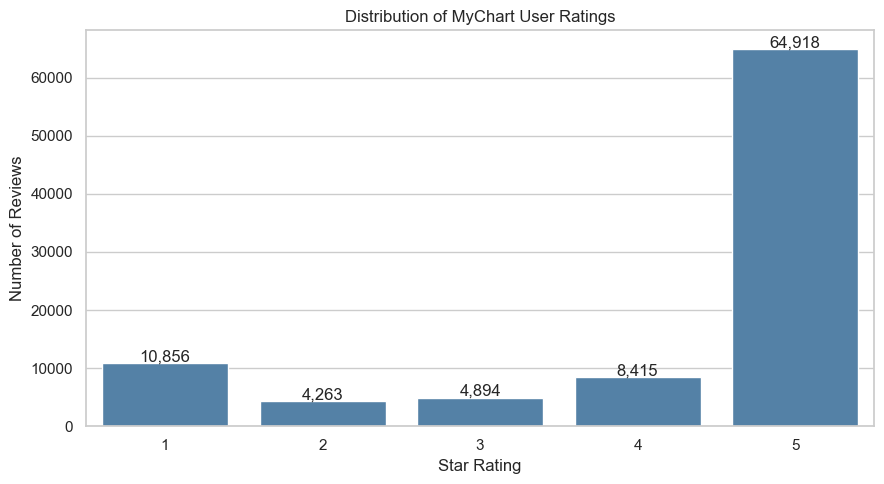

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

rating_counts = (
    mychart_clean["score"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .sort_index()
)

rating_percentages = (
    rating_counts / rating_counts.sum() * 100
).round(2)

rating_summary = pd.DataFrame({
    "Review Count": rating_counts,
    "Percentage": rating_percentages
})

display(rating_summary)

print("Average rating:", round(mychart_clean["score"].mean(), 2))
print("Median rating:", mychart_clean["score"].median())

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    color="steelblue"
)

for i, count in enumerate(rating_counts.values):
    ax.text(i, count + 300, f"{count:,}", ha="center")

plt.title("Distribution of MyChart User Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

,review_length_words,review_length_chars
count,93346.000000,93346.000000
mean,18.750820,100.762154
std,19.762481,106.496072
min,1.000000,1.000000
25%,5.000000,27.000000
50%,12.000000,66.000000
75%,25.000000,134.000000
max,675.000000,3699.000000


Average review length (words): 18.75
Median review length (words): 12.0


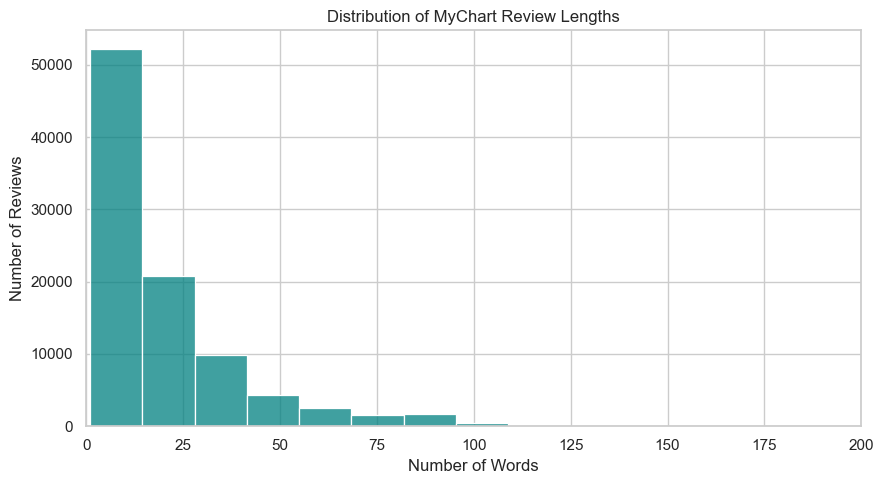

In [9]:
length_summary = mychart_clean[
    ["review_length_words", "review_length_chars"]
].describe()

display(length_summary)

print(
    "Average review length (words):",
    round(mychart_clean["review_length_words"].mean(), 2)
)

print(
    "Median review length (words):",
    mychart_clean["review_length_words"].median()
)

plt.figure(figsize=(9, 5))

sns.histplot(
    mychart_clean["review_length_words"],
    bins=50,
    color="teal"
)

plt.title("Distribution of MyChart Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.xlim(0, 200)
plt.tight_layout()
plt.show()

,count,mean,median
score,,,
1,10856,25.73,18.0
2,4263,29.70,23.0
3,4894,28.39,21.0
4,8415,22.11,15.0
5,64918,15.70,10.0


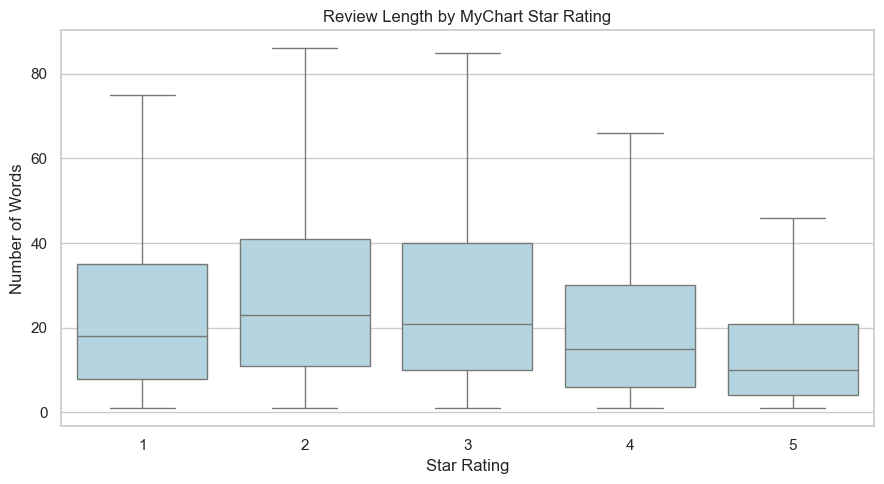

In [8]:
length_by_rating = (
    mychart_clean
    .groupby("score")["review_length_words"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(length_by_rating)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=mychart_clean,
    x="score",
    y="review_length_words",
    color="lightblue",
    showfliers=False
)

plt.title("Review Length by MyChart Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()


### 3.1 Interpretation of Exploratory Findings

**Rating distribution:** Among the 93,346 cleaned MyChart reviews, 69.55% received five stars, while 11.63% received one star. The average rating was 4.20 and the median rating was 5. This indicates that highly positive ratings dominate the collected reviews, although a substantial set of lower-rated experiences remains available for analysis.

**Review length:** Reviews contained an average of 18.75 words and a median of 12 words. The difference between the mean and median, together with a maximum of 675 words, suggests a right-skewed distribution in which most reviews are relatively short but some are much longer.

**Rating and review length:** Two-star reviews averaged 29.70 words, compared with 15.70 words for five-star reviews. One-star reviews averaged 25.73 words. This suggests that lower-rated reviewers often provide more written detail, potentially offering richer material for extracting user-reported problems.

**Business implications:** Product managers and digital healthcare stakeholders should not rely exclusively on aggregate star ratings. Examining the content of lower-rated reviews may reveal actionable concerns that are obscured by the overall positive rating distribution. Subsequent text-mining analyses will investigate recurring terms, sentiment, and reported issues across review categories.

**Limitations:** These findings describe the collected review dataset rather than all MyChart users. Review authors are self-selected, and star ratings do not necessarily correspond to specific technical or healthcare-access problems. Descriptive associations between rating and review length should not be interpreted as causal relationships.



## 4. Text Preprocessing and Keyword Analysis

This section prepares MyChart review text for exploratory natural language processing.

The objectives are to:
- Normalize review text and remove common stopwords.
- Identify frequently occurring words (unigrams).
- Identify commonly occurring two-word combinations (bigrams).
- Explore vocabulary that may help identify user-reported experiences and concerns.

The preprocessing preserves the original review text for later sentiment analysis and interpretation. Frequent terms are descriptive signals, not automatically validated issue categories.


In [10]:

import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Preserve original review text for later analysis
mychart_clean["original_text"] = mychart_clean["content"].copy()

# Keep negation terms because they may carry important meaning
custom_stopwords = set(ENGLISH_STOP_WORDS) - {
    "no", "not", "nor", "never"
}

def preprocess_review(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text)
    tokens = [
        token for token in tokens
        if token not in custom_stopwords and len(token) > 1
    ]
    return " ".join(tokens)

mychart_clean["processed_text"] = (
    mychart_clean["original_text"].apply(preprocess_review)
)

print("Reviews processed:", len(mychart_clean))
print("Empty processed reviews:",
      mychart_clean["processed_text"].eq("").sum())

display(
    mychart_clean[
        ["original_text", "processed_text"]
    ].head(10)
)


Reviews processed: 93346
Empty processed reviews: 306


,original_text,processed_text
480,very easy to use and follow up with my care,easy use follow care
481,"Best information, since the wheel.",best information wheel
482,i found everything i was looking for plus some...,looking plus thank chart
483,MyChart is an incredibly convenient app for ma...,mychart incredibly convenient app managing hea...
484,"it's very helpful, all involved are able to ac...",it's helpful involved able access information ...
485,"Since the update, I cannot send messages to th...",update send messages providers son's pcp video...
486,Great app,great app
487,it's a great way for me to talk to my doctors ...,it's great way talk doctors appointment change...
488,It would be very helpful if I could find the a...,helpful app phone umc medical center instead m...
489,thanks for it I love it,thanks love


,Term,Frequency
39,app,36030
240,easy,17660
486,love,16906
338,great,14169
931,use,14038
741,results,12500
43,appointments,11422
556,not,10322
421,it,9340
507,medical,8949


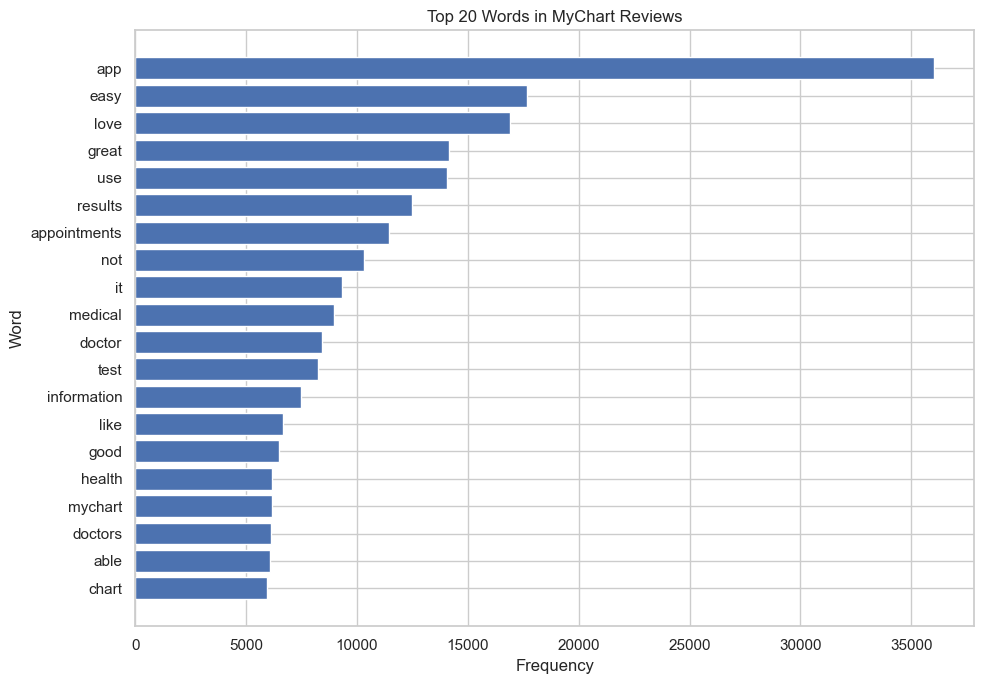

In [13]:

from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import pandas as pd

texts = mychart_clean.loc[
    mychart_clean["processed_text"].ne(""),
    "processed_text"
]

unigram_vectorizer = CountVectorizer(
    ngram_range=(1, 1),
    max_features=1000
)

unigram_matrix = unigram_vectorizer.fit_transform(texts)

unigram_counts = unigram_matrix.sum(axis=0).A1

unigram_df = pd.DataFrame({
    "Term": unigram_vectorizer.get_feature_names_out(),
    "Frequency": unigram_counts
}).sort_values("Frequency", ascending=False)

display(unigram_df.head(20))

top_unigrams = unigram_df.head(20).sort_values("Frequency")

plt.figure(figsize=(10, 7))
plt.barh(top_unigrams["Term"], top_unigrams["Frequency"])
plt.title("Top 20 Words in MyChart Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


,Bigram,Frequency
340,easy use,8096
872,test results,7066
566,love app,4484
394,great app,3852
944,user friendly,1615
332,easy navigate,1547
61,app easy,1487
620,medical records,1387
435,health care,1259
613,medical information,1218


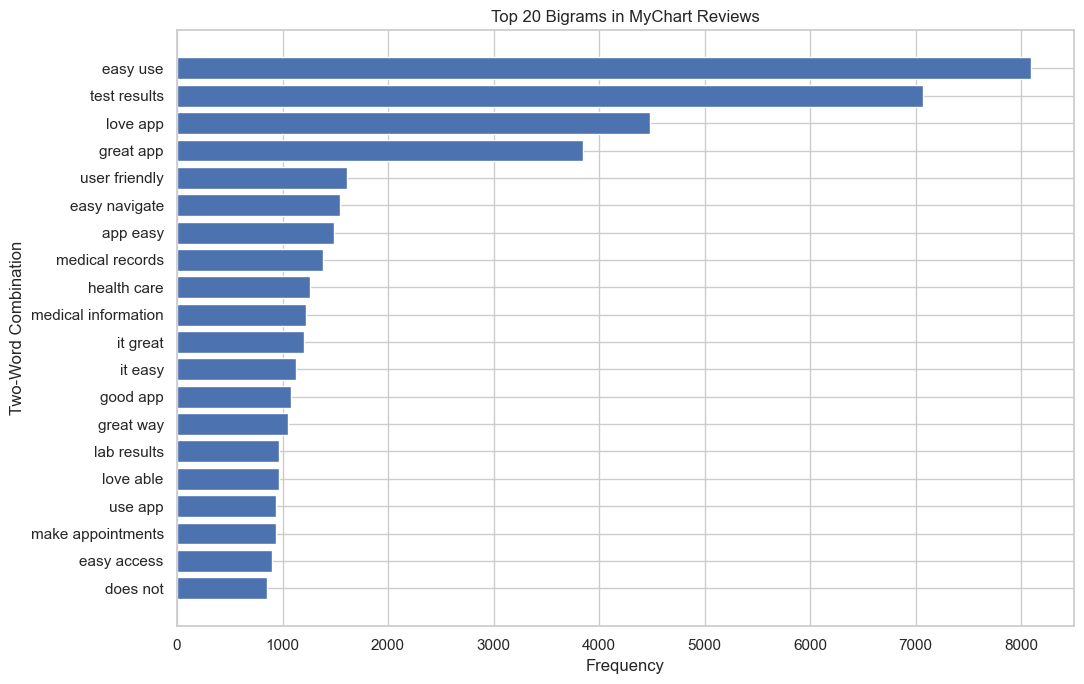

In [14]:

bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=1000
)

bigram_matrix = bigram_vectorizer.fit_transform(texts)

bigram_counts = bigram_matrix.sum(axis=0).A1

bigram_df = pd.DataFrame({
    "Bigram": bigram_vectorizer.get_feature_names_out(),
    "Frequency": bigram_counts
}).sort_values("Frequency", ascending=False)

display(bigram_df.head(20))

top_bigrams = bigram_df.head(20).sort_values("Frequency")

plt.figure(figsize=(11, 7))
plt.barh(top_bigrams["Bigram"], top_bigrams["Frequency"])
plt.title("Top 20 Bigrams in MyChart Reviews")
plt.xlabel("Frequency")
plt.ylabel("Two-Word Combination")
plt.tight_layout()
plt.show()


In [17]:
pip install vaderSentiment

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



## 5. Sentiment Analysis Using VADER

This section applies VADER, a lexicon-based sentiment analysis method, to the original MyChart review text.

The objectives are to:
- Classify reviews into positive, neutral, and negative sentiment.
- Compare sentiment classifications with user star ratings.
- Identify disagreements between text sentiment and numerical ratings.
- Assess the usefulness and limitations of sentiment analysis for understanding patient-reported experiences.

VADER provides an interpretable baseline rather than a validated measure of patient trust or healthcare application quality.


In [19]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

# Apply VADER to the original text, not the stopword-removed text
mychart_clean["vader_compound"] = (
    mychart_clean["original_text"]
    .apply(lambda text: analyzer.polarity_scores(str(text))["compound"])
)

def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

mychart_clean["vader_sentiment"] = (
    mychart_clean["vader_compound"].apply(classify_sentiment)
)

sentiment_summary = (
    mychart_clean["vader_sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
    .rename_axis("Sentiment")
    .reset_index(name="Review Count")
)

sentiment_summary["Percentage"] = (
    sentiment_summary["Review Count"]
    / len(mychart_clean) * 100
).round(2)

display(sentiment_summary)


,Sentiment,Review Count,Percentage
0,Positive,70465,75.49
1,Neutral,11588,12.41
2,Negative,11293,12.10


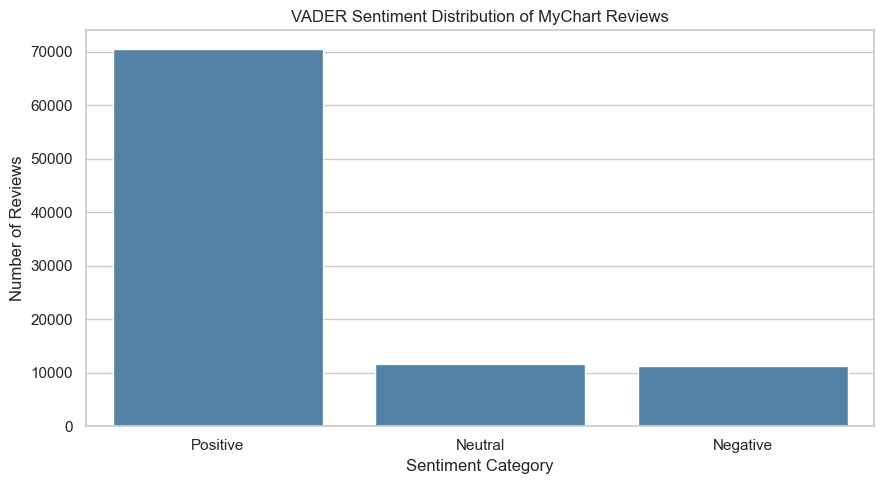

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=sentiment_summary,
    x="Sentiment",
    y="Review Count",
    order=["Positive", "Neutral", "Negative"],
    color="steelblue"
)

plt.title("VADER Sentiment Distribution of MyChart Reviews")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


vader_sentiment,Positive,Neutral,Negative
score,,,
1,2182,3059,5615
2,1263,985,2015
3,2062,1117,1715
4,6483,1059,873
5,58475,5368,1075


vader_sentiment,Positive,Neutral,Negative
score,,,
1,20.10,28.18,51.72
2,29.63,23.11,47.27
3,42.13,22.82,35.04
4,77.04,12.58,10.37
5,90.08,8.27,1.66


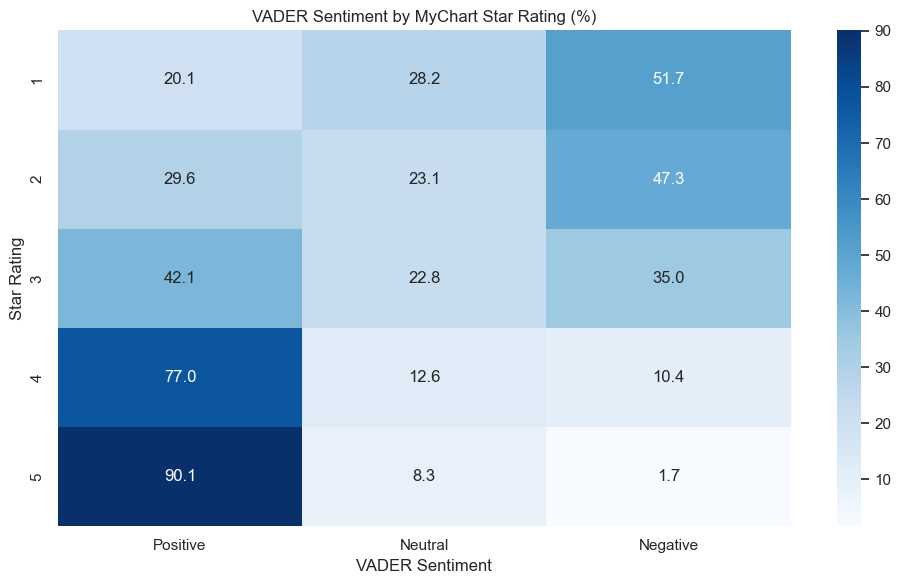

In [21]:

rating_sentiment_counts = pd.crosstab(
    mychart_clean["score"],
    mychart_clean["vader_sentiment"]
).reindex(
    index=[1, 2, 3, 4, 5],
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0
)

rating_sentiment_pct = (
    rating_sentiment_counts
    .div(rating_sentiment_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

display(rating_sentiment_counts)
display(rating_sentiment_pct)

plt.figure(figsize=(10, 6))
sns.heatmap(
    rating_sentiment_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("VADER Sentiment by MyChart Star Rating (%)")
plt.xlabel("VADER Sentiment")
plt.ylabel("Star Rating")
plt.tight_layout()
plt.show()


In [22]:

# Positive text sentiment despite a low star rating
low_rating_positive = mychart_clean[
    (mychart_clean["score"] <= 2) &
    (mychart_clean["vader_sentiment"] == "Positive")
]

# Negative text sentiment despite a high star rating
high_rating_negative = mychart_clean[
    (mychart_clean["score"] >= 4) &
    (mychart_clean["vader_sentiment"] == "Negative")
]

print("Low-rated reviews with positive VADER sentiment:",
      len(low_rating_positive))

print("High-rated reviews with negative VADER sentiment:",
      len(high_rating_negative))

# Avoid printing identifiable review content or IDs in public outputs.
print(
    "Total rating-sentiment disagreements:",
    len(low_rating_positive) + len(high_rating_negative)
)


Low-rated reviews with positive VADER sentiment: 3445
High-rated reviews with negative VADER sentiment: 1948
Total rating-sentiment disagreements: 5393
